# PDB x UniProt integration - cross-database analysis

The integration layer of the pipelines connects **structure** (PDB) with
**annotation** (UniProt): `align_uniprot.py` blastps every PDB chain against
Swiss-Prot (`meta_blastp5.py` preselects hits) and the SQL view
`view_pdb_uniprot` joins high-confidence chain->accession mappings (bit_score
>= 50, evalue <= 1e-10, identity >= 0.3) with chain sequences, UniProt
sequences, method and resolution.

Data used in this notebook:

| source | SQL object | content |
|---|---|---|
| structure mapping | `view_pdb_uniprot` (from `align_uniprot`) | chain_id, pdb_id, uniprot_acc, identity, chain_seq, pro_seq, method, resolution |
| curated proteome | `uniprot` | all Swiss-Prot entries |
| cross-references | `uniprot_dbxrefs` | entry links incl. PDB / AlphaFoldDB |

**Outputs**
- figures -> `doc/figures/integration_*.png`
- statistical tables -> `doc/stats/integration_*.csv` (ready for further analysis)

In [1]:
import sys
from collections import Counter
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib_venn import venn2

def _locate_doc_dir():
    for start in (Path.cwd(), *Path.cwd().parents):
        if (start / 'doc' / 'nb_utils.py').is_file():
            return start / 'doc'
    return Path.cwd()

doc_dir = _locate_doc_dir()
sys.path.insert(0, str(doc_dir))
from nb_utils import (query_df, query_scalar, save_fig, save_csv,
                      describe_groups, pairwise_mannwhitney,
                      FIG_DIR, STAT_DIR, PALETTE)

print('figures ->', FIG_DIR)
print('stats   ->', STAT_DIR)

figures -> /home/yuan/bio/bio_omics/doc/figures
stats   -> /home/yuan/bio/bio_omics/doc/stats


## 1. Integration coverage

How much of each database does the mapping bridge?
- PDB entries with at least one confident Swiss-Prot match,
- Swiss-Prot accessions observed in the structural archive (blastp route),
- the same number via depositor cross-references (`uniprot_dbxrefs.db_name='PDB'`).

In [2]:
n_pdb_total = query_scalar('SELECT COUNT(*) FROM pdb')
n_uni_total = query_scalar('SELECT COUNT(*) FROM uniprot')
n_map_rows = query_scalar('SELECT COUNT(*) FROM view_pdb_uniprot')
n_map_pdb = query_scalar('SELECT COUNT(DISTINCT pdb_id) FROM view_pdb_uniprot')
n_map_acc = query_scalar('SELECT COUNT(DISTINCT uniprot_acc) FROM view_pdb_uniprot')
n_xref_acc = query_scalar(
    "SELECT COUNT(DISTINCT uniprot_acc) FROM uniprot_dbxrefs WHERE db_name='PDB'")

coverage = pd.DataFrame([
    {'metric': 'pdb_entries_total', 'value': n_pdb_total},
    {'metric': 'pdb_entries_mapped_to_swissprot', 'value': n_map_pdb},
    {'metric': 'pdb_mapped_fraction', 'value': round(n_map_pdb / n_pdb_total, 4)},
    {'metric': 'swissprot_entries_total', 'value': n_uni_total},
    {'metric': 'swissprot_via_blastp_mapping', 'value': n_map_acc},
    {'metric': 'swissprot_blastp_fraction', 'value': round(n_map_acc / n_uni_total, 4)},
    {'metric': 'swissprot_with_pdb_xref', 'value': n_xref_acc},
    {'metric': 'swissprot_pdb_xref_fraction', 'value': round(n_xref_acc / n_uni_total, 4)},
    {'metric': 'chain_level_mapping_rows', 'value': n_map_rows},
])
save_csv(coverage, 'integration_coverage')
coverage

saved table: /home/yuan/bio/bio_omics/doc/stats/integration_coverage.csv  shape=(9, 2)


,metric,value
0,pdb_entries_total,244584.0000
1,pdb_entries_mapped_to_swissprot,218368.0000
2,pdb_mapped_fraction,0.8928
3,swissprot_entries_total,575503.0000
4,swissprot_via_blastp_mapping,49926.0000
5,swissprot_blastp_fraction,0.0868
6,swissprot_with_pdb_xref,39017.0000
7,swissprot_pdb_xref_fraction,0.0678
8,chain_level_mapping_rows,671936.0000


## 2. Overlap of the two discovery routes

Two independent routes lead from Swiss-Prot to structure: sequence search of
PDB chains (blastp mapping) versus depositor-provided cross-references. The
Venn diagram compares the covered accession sets; the intersection validates
the automated route, while its extra accessions are proteins whose structures
exist but were never xref-ed.

saved figure: /home/yuan/bio/bio_omics/doc/figures/integration_uniprot_pdb_venn.png
saved table: /home/yuan/bio/bio_omics/doc/stats/integration_venn_sets.csv  shape=(4, 2)


,set,n
0,blastp_mapping_only,19299
1,pdb_xref_only,8390
2,both,30627
3,blastp_union,58316


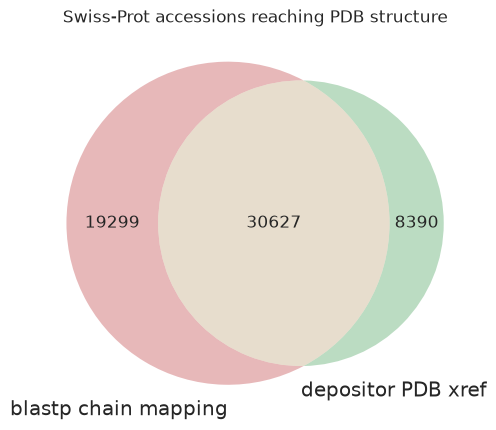

In [3]:
blast_accs = set(query_df(
    'SELECT DISTINCT uniprot_acc AS acc FROM view_pdb_uniprot')['acc'])
xref_accs = set(query_df(
    "SELECT DISTINCT uniprot_acc AS acc FROM uniprot_dbxrefs "
    "WHERE db_name='PDB'")['acc'])
both = len(blast_accs & xref_accs)

fig, ax = plt.subplots(figsize=(6.5, 5))
venn2(subsets=(len(blast_accs) - both, len(xref_accs) - both, both),
      set_labels=('blastp chain mapping', 'depositor PDB xref'), ax=ax)
ax.set_title('Swiss-Prot accessions reaching PDB structure')
save_fig(fig, 'integration_uniprot_pdb_venn')

venn_tbl = pd.DataFrame([
    {'set': 'blastp_mapping_only', 'n': len(blast_accs) - both},
    {'set': 'pdb_xref_only', 'n': len(xref_accs) - both},
    {'set': 'both', 'n': both},
    {'set': 'blastp_union', 'n': len(blast_accs | xref_accs)},
])
save_csv(venn_tbl, 'integration_venn_sets')
venn_tbl

## 3. Sequence identity of chain->protein mappings

The blastp `identity` of each mapped chain tells how close the crystallized
sequence is to its Swiss-Prot counterpart. The distribution separates
*almost-identical* structures of the canonical protein (engineered constructs,
species variants) from more distant homologues crystallized as surrogates.

saved table: /home/yuan/bio/bio_omics/doc/stats/integration_identity_stats.csv  shape=(1, 9)


saved figure: /home/yuan/bio/bio_omics/doc/figures/integration_identity_distribution.png


,n_chains,mean,std,q25,median,q75,max,fraction_identity_ge_0.9,fraction_identity_lt_0.5
0,671936,0.894541,0.176918,0.884615,0.984848,1.0,1.0,0.731515,0.069889


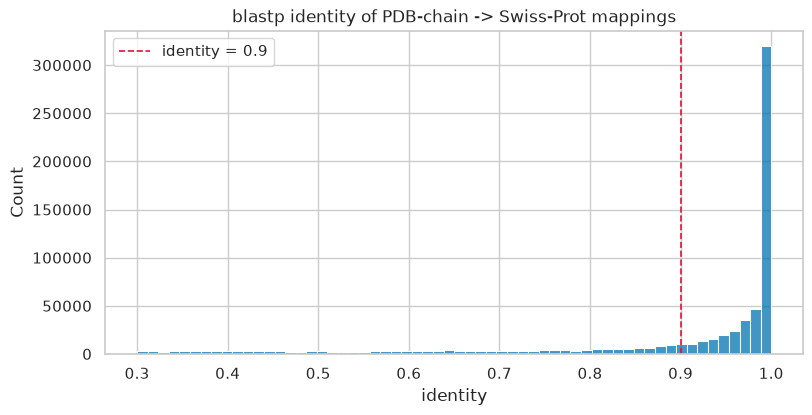

In [4]:
ident = query_df('SELECT identity FROM view_pdb_uniprot')
ident['identity'] = ident['identity'].astype(float)

summ = pd.DataFrame([{
    'n_chains': len(ident),
    'mean': ident['identity'].mean(),
    'std': ident['identity'].std(),
    'q25': ident['identity'].quantile(0.25),
    'median': ident['identity'].median(),
    'q75': ident['identity'].quantile(0.75),
    'max': ident['identity'].max(),
    'fraction_identity_ge_0.9': (ident['identity'] >= 0.9).mean(),
    'fraction_identity_lt_0.5': (ident['identity'] < 0.5).mean(),
}])
save_csv(summ, 'integration_identity_stats')

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.histplot(ident['identity'], bins=60, ax=ax, color=PALETTE[0])
ax.axvline(0.9, color='crimson', ls='--', lw=1.2, label='identity = 0.9')
ax.legend()
ax.set_title('blastp identity of PDB-chain -> Swiss-Prot mappings')
ax.set_xlabel('identity')
save_fig(fig, 'integration_identity_distribution')
summ

## 4. Resolution and identity - independent axes of structural knowledge

Does the archive resolve *conserved* proteins better than fast-evolving ones?
We correlate blastp identity against structure resolution (Spearman, both
non-Gaussian) and compare identity across experimental methods (Kruskal-Wallis
+ pairwise Mann-Whitney). A weak dependence would mean method choice and
evolutionary conservation are independent axes of structural biology.

saved table: /home/yuan/bio/bio_omics/doc/stats/integration_identity_resolution_correlation.csv  shape=(1, 5)
Spearman rho=-0.0009, p=4.581e-01, n=659499


saved figure: /home/yuan/bio/bio_omics/doc/figures/integration_resolution_vs_identity.png


,comparison,method,n,rho,p_value
0,identity vs resolution,spearman,659499,-0.0009,0.458057


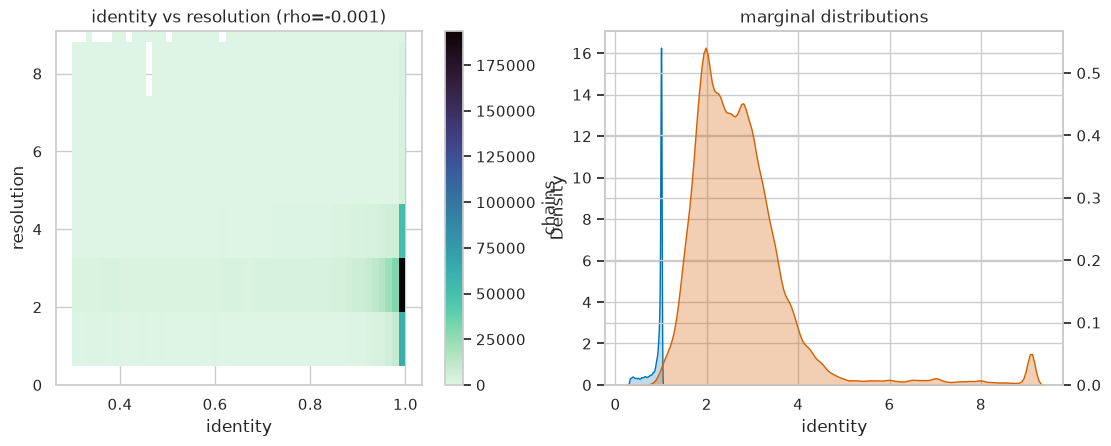

In [5]:
ident_meta = query_df(
    'SELECT identity, resolution, structure_method FROM view_pdb_uniprot')
ident_meta['identity'] = ident_meta['identity'].astype(float)
ident_meta['resolution'] = pd.to_numeric(ident_meta['resolution'], errors='coerce')

sub = ident_meta.dropna(subset=['resolution'])
rho, p_sp = stats.spearmanr(sub['identity'], sub['resolution'])
corr = pd.DataFrame([
    {'comparison': 'identity vs resolution',
     'method': 'spearman', 'n': len(sub),
     'rho': round(rho, 4), 'p_value': p_sp},
])
save_csv(corr, 'integration_identity_resolution_correlation')
print(f'Spearman rho={rho:.4f}, p={p_sp:.3e}, n={len(sub)}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sns.histplot(data=sub, x='identity', y='resolution', bins=50, cmap='mako_r',
             cbar=True, cbar_kws={'label': 'chains'}, ax=ax[0])
ax[0].set_ylim(0, sub['resolution'].quantile(0.99))
ax[0].set_title(f'identity vs resolution (rho={rho:.3f})')
sns.kdeplot(sub['identity'], ax=ax[1], fill=True, label='identity',
            color=PALETTE[0])
ax2 = ax[1].twinx()
sns.kdeplot(sub['resolution'].clip(upper=sub['resolution'].quantile(0.99)),
            ax=ax2, fill=True, color=PALETTE[3], alpha=0.3, label='resolution')
ax[1].set_xlabel('identity')
ax2.set_xlabel('')
ax2.set_ylabel('')
ax[1].set_title('marginal distributions')
save_fig(fig, 'integration_resolution_vs_identity')
corr

saved table: /home/yuan/bio/bio_omics/doc/stats/integration_identity_method_tests.csv  shape=(1, 9)
Kruskal-Wallis H=603.6, p=1.677e-130


/tmp/ipykernel_2118168/3419337786.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=subm, x='structure_method', y='identity', ax=ax,


saved figure: /home/yuan/bio/bio_omics/doc/figures/integration_identity_by_method.png


,group_a,group_b,n_a,n_b,median_a,median_b,U,p_value,p_bonferroni
0,electron microscopy,x-ray diffraction,197017,461646,0.981707,0.984733,4.695824e+10,4.163172e-102,4.163172e-102


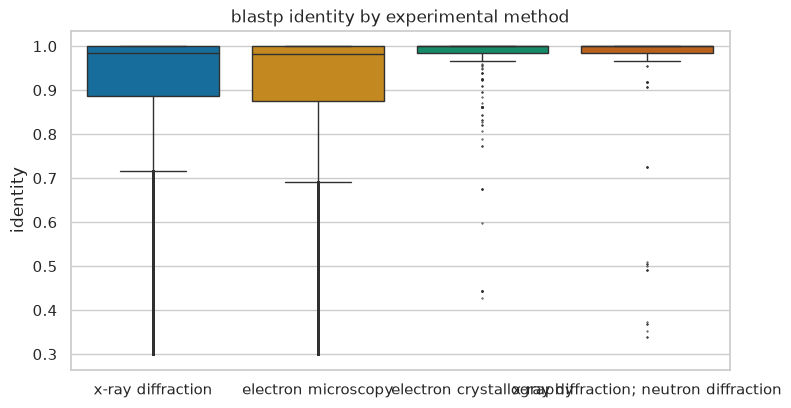

In [6]:
top_methods = ident_meta['structure_method'].value_counts().head(4).index.tolist()
subm = ident_meta[ident_meta['structure_method'].isin(top_methods)]
samples = [g['identity'].to_numpy() for _, g in subm.groupby('structure_method')]
H, p_kw = stats.kruskal(*samples)
tests = pairwise_mannwhitney(subm, 'structure_method', 'identity', min_n=1000)
save_csv(tests, 'integration_identity_method_tests')
print(f'Kruskal-Wallis H={H:.1f}, p={p_kw:.3e}')

fig, ax = plt.subplots(figsize=(8.5, 4.4))
sns.boxplot(data=subm, x='structure_method', y='identity', ax=ax,
            palette='colorblind', fliersize=0.5)
ax.set_title('blastp identity by experimental method')
ax.set_xlabel('')
save_fig(fig, 'integration_identity_by_method')
tests

**Interpretation.** Identity and resolution are essentially uncorrelated:
structural biology does not simply target conserved proteins at high
resolution - crystallographers frequently crystallize distant homologues or
stable constructs, while method families differ modestly in the identity of
their targets. Practically, sequence-identity filters should be applied
independently of resolution filters when curating structure/sequence pairs for
modelling.

## 5. Crystallized variation - substitutions between PDB chains and Swiss-Prot

For high-identity pairs (identity >= 0.9) every sequence difference is a
*crystallized variant*: engineered stabilizing mutations, expression-construct
artifacts or natural polymorphisms that still yielded structures. Sampling 20,000 mapped chains we align each construct to its parent
protein (25-mer anchor offsets, best candidate by mismatch count) and compute:

- the per-chain mutation rate,
- the amino-acid substitution spectrum (which exchanges are tolerated).

20000 high-identity chains sampled


saved table: /home/yuan/bio/bio_omics/doc/stats/integration_mutation_rate_stats.csv  shape=(1, 10)
saved table: /home/yuan/bio/bio_omics/doc/stats/integration_mutation_rates.csv
saved table: /home/yuan/bio/bio_omics/doc/stats/integration_substitution_counts.csv  shape=(380, 3)


saved figure: /home/yuan/bio/bio_omics/doc/figures/integration_mutation_rate.png


,n_chains,mean,std,q25,median,q75,q95,max,median_offset_aa,fraction_truncated_construct
0,19890,0.129392,0.219608,0.0,0.004975,0.2,0.59061,0.984375,19,0.858522


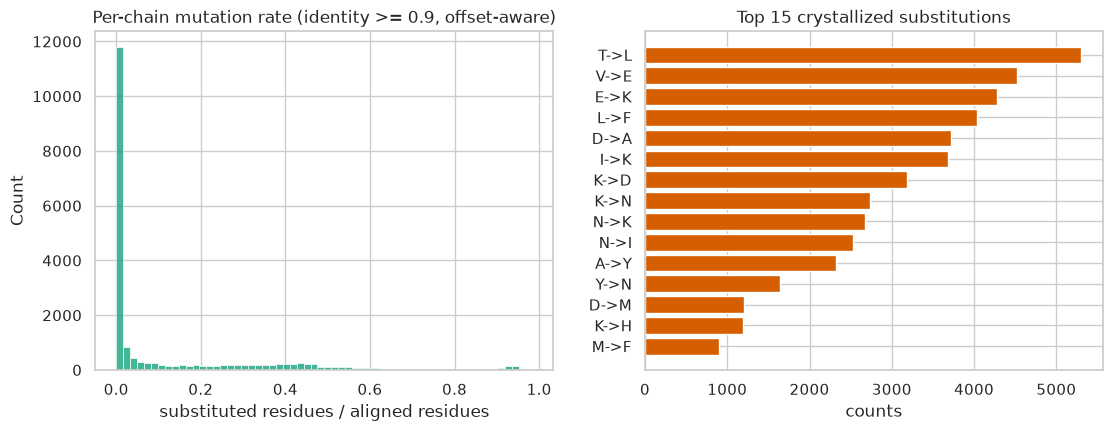

In [7]:
AA20 = set('ACDEFGHIKLMNPQRSTVWY')
pairs = query_df("""
    SELECT pdb_id, uniprot_acc, identity, chain_seq, pro_seq
    FROM view_pdb_uniprot
    WHERE identity >= 0.9 AND chain_seq IS NOT NULL AND pro_seq IS NOT NULL
    ORDER BY RAND()
    LIMIT 20000
""")
print(f'{len(pairs)} high-identity chains sampled')

def candidate_offsets(chain_seq, pro_seq):
    # anchor offsets of the crystallized construct inside the full protein
    L = len(chain_seq)
    cand = {0, max(0, len(pro_seq) - L)}
    for start in (0, L // 2, max(0, L - 25)):
        window = chain_seq[start:start + 25]
        if len(window) == 25:
            idx = pro_seq.find(window)
            if idx >= 0:
                cand.add(idx - start)
    return cand

rates, offsets, sub_counts = [], [], Counter()
for s1, s2 in zip(pairs['chain_seq'], pairs['pro_seq']):
    if not isinstance(s1, str) or not isinstance(s2, str):
        continue
    best = None  # (mutated, aligned, offset)
    for off in candidate_offsets(s1, s2):
        lo, hi = max(0, -off), min(len(s1), len(s2) - off)
        if hi - lo < 30:
            continue
        aligned = mutated = 0
        for i in range(lo, hi):
            a, b = s1[i], s2[i + off]
            if a in AA20 and b in AA20:
                aligned += 1
                if a != b:
                    mutated += 1
        if aligned >= 30 and (best is None or mutated < best[0]):
            best = (mutated, aligned, off)
    if best:
        mutated, aligned, off = best
        rates.append(mutated / aligned)
        offsets.append(off)
        lo, hi = max(0, -off), min(len(s1), len(s2) - off)
        for i in range(lo, hi):
            a, b = s1[i], s2[i + off]
            if a in AA20 and b in AA20 and a != b:
                sub_counts[(a, b)] += 1

rates = pd.Series(rates, name='mutation_rate')
offs = pd.Series(offsets)
rate_tbl = pd.DataFrame([{
    'n_chains': len(rates), 'mean': rates.mean(), 'std': rates.std(),
    'q25': rates.quantile(0.25), 'median': rates.median(),
    'q75': rates.quantile(0.75), 'q95': rates.quantile(0.95),
    'max': rates.max(),
    'median_offset_aa': int(offs.median()),
    'fraction_truncated_construct': float((offs > 0).mean()),
}])
save_csv(rate_tbl, 'integration_mutation_rate_stats')
rates.to_frame().to_csv(STAT_DIR / 'integration_mutation_rates.csv', index=False)
print('saved table:', STAT_DIR / 'integration_mutation_rates.csv')

sub_df = pd.DataFrame(
    [{'aa_pdb': a, 'aa_uniprot': b, 'n': n} for (a, b), n in sub_counts.items()])
save_csv(sub_df.sort_values('n', ascending=False), 'integration_substitution_counts')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
sns.histplot(rates, bins=60, ax=ax[0], color=PALETTE[2])
ax[0].set_title('Per-chain mutation rate (identity >= 0.9, offset-aware)')
ax[0].set_xlabel('substituted residues / aligned residues')
top_subs = sub_df.head(15).sort_values('n')
ax[1].barh(top_subs['aa_pdb'] + '->' + top_subs['aa_uniprot'],
           top_subs['n'], color=PALETTE[3])
ax[1].set_title('Top 15 crystallized substitutions')
ax[1].set_xlabel('counts')
save_fig(fig, 'integration_mutation_rate')
rate_tbl

**Interpretation.** Most high-identity structures differ from Swiss-Prot in
only one or a few residues - the canonical crystallized variants. The
substitution spectrum is dominated by physicochemically conservative exchanges
that rarely destabilize a fold, consistent with crystallization selecting
functional, well-folded proteins.

saved figure: /home/yuan/bio/bio_omics/doc/figures/integration_substitution_matrix.png


,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
A,0.000,0.017,0.056,0.067,0.047,0.075,0.025,0.064,0.057,0.109,0.024,0.042,0.047,0.045,0.060,0.070,0.065,0.079,0.015,0.035
C,0.081,0.000,0.055,0.059,0.046,0.069,0.023,0.058,0.055,0.100,0.022,0.041,0.043,0.038,0.049,0.085,0.057,0.071,0.015,0.034
D,0.076,0.018,0.000,0.069,0.051,0.066,0.024,0.064,0.062,0.108,0.022,0.050,0.047,0.041,0.053,0.065,0.055,0.079,0.015,0.037
E,0.079,0.017,0.060,0.000,0.049,0.067,0.024,0.066,0.068,0.110,0.025,0.044,0.046,0.045,0.056,0.065,0.055,0.073,0.014,0.037
F,0.071,0.018,0.056,0.063,0.000,0.070,0.025,0.065,0.063,0.101,0.023,0.048,0.048,0.041,0.053,0.070,0.059,0.071,0.015,0.041
G,0.081,0.021,0.058,0.068,0.049,0.000,0.024,0.064,0.057,0.103,0.023,0.044,0.049,0.042,0.053,0.071,0.060,0.082,0.014,0.037
H,0.071,0.020,0.052,0.066,0.050,0.063,0.000,0.059,0.055,0.101,0.024,0.044,0.046,0.043,0.053,0.065,0.059,0.074,0.014,0.041
I,0.075,0.016,0.060,0.071,0.047,0.067,0.023,0.000,0.064,0.107,0.025,0.048,0.044,0.041,0.052,0.067,0.061,0.082,0.014,0.036
K,0.076,0.017,0.055,0.077,0.047,0.065,0.025,0.067,0.000,0.106,0.024,0.048,0.047,0.041,0.058,0.065,0.059,0.072,0.014,0.038
L,0.082,0.018,0.061,0.075,0.048,0.072,0.026,0.066,0.067,0.000,0.024,0.047,0.047,0.045,0.060,0.070,0.063,0.078,0.015,0.037


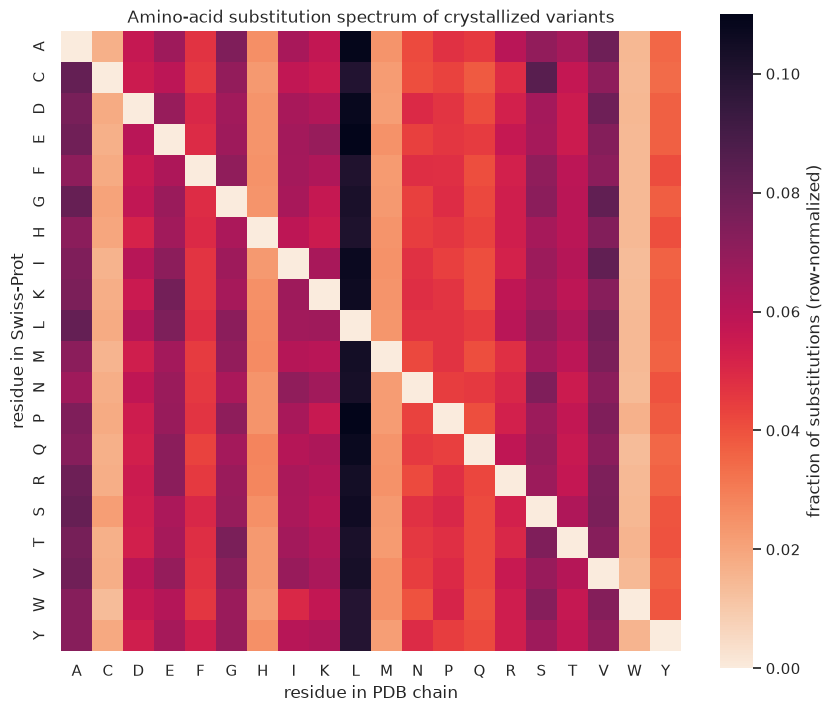

In [8]:
order = list('ACDEFGHIKLMNPQRSTVWY')
mat = pd.DataFrame(0.0, index=order, columns=order)
for _, row in sub_df.iterrows():
    mat.loc[row['aa_uniprot'], row['aa_pdb']] = row['n']
mat_norm = mat.div(mat.sum(axis=1).replace(0, 1), axis=0)  # row-normalized
mat_arr = mat_norm.to_numpy(copy=True)  # writable copy
np.fill_diagonal(mat_arr, 0)  # highlight exchanges only
mat_norm = pd.DataFrame(mat_arr, index=mat_norm.index, columns=mat_norm.columns)

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(mat_norm, ax=ax, cmap='rocket_r', square=True,
            cbar_kws={'label': 'fraction of substitutions (row-normalized)'})
ax.set_xlabel('residue in PDB chain')
ax.set_ylabel('residue in Swiss-Prot')
ax.set_title('Amino-acid substitution spectrum of crystallized variants')
save_fig(fig, 'integration_substitution_matrix')
mat_norm.round(3)

## 6. Organisms behind the structures

Joining the mapping with `uniprot.organism` shows which species the solved
structures belong to (as opposed to which organism the *annotation* favours).
Model microbes and human dominate - the taxonomic lens of experimental
structural biology.

saved table: /home/yuan/bio/bio_omics/doc/stats/integration_top_organisms.csv  shape=(25, 4)


saved figure: /home/yuan/bio/bio_omics/doc/figures/integration_top_organisms.png


,organism,n_pdb_entries,n_proteins,mean_identity
0,Homo sapiens (Human),65535,7571,0.927
1,Mus musculus (Mouse),15712,3112,0.903
2,Rattus norvegicus (Rat),10399,1396,0.956
3,Escherichia coli (strain K12),7611,1254,0.913
4,Saccharomyces cerevisiae (strain ATCC 204508 /...,6527,2068,0.950
5,Bos taurus (Bovine),5580,897,0.953
6,Severe acute respiratory syndrome coronavirus ...,5110,9,0.959
7,Pongo abelii (Sumatran orangutan) (Pongo pygma...,4971,494,0.963
8,Bacillus subtilis (strain 168),4392,1245,0.733
9,Arabidopsis thaliana (Mouse-ear cress),4113,1558,0.824


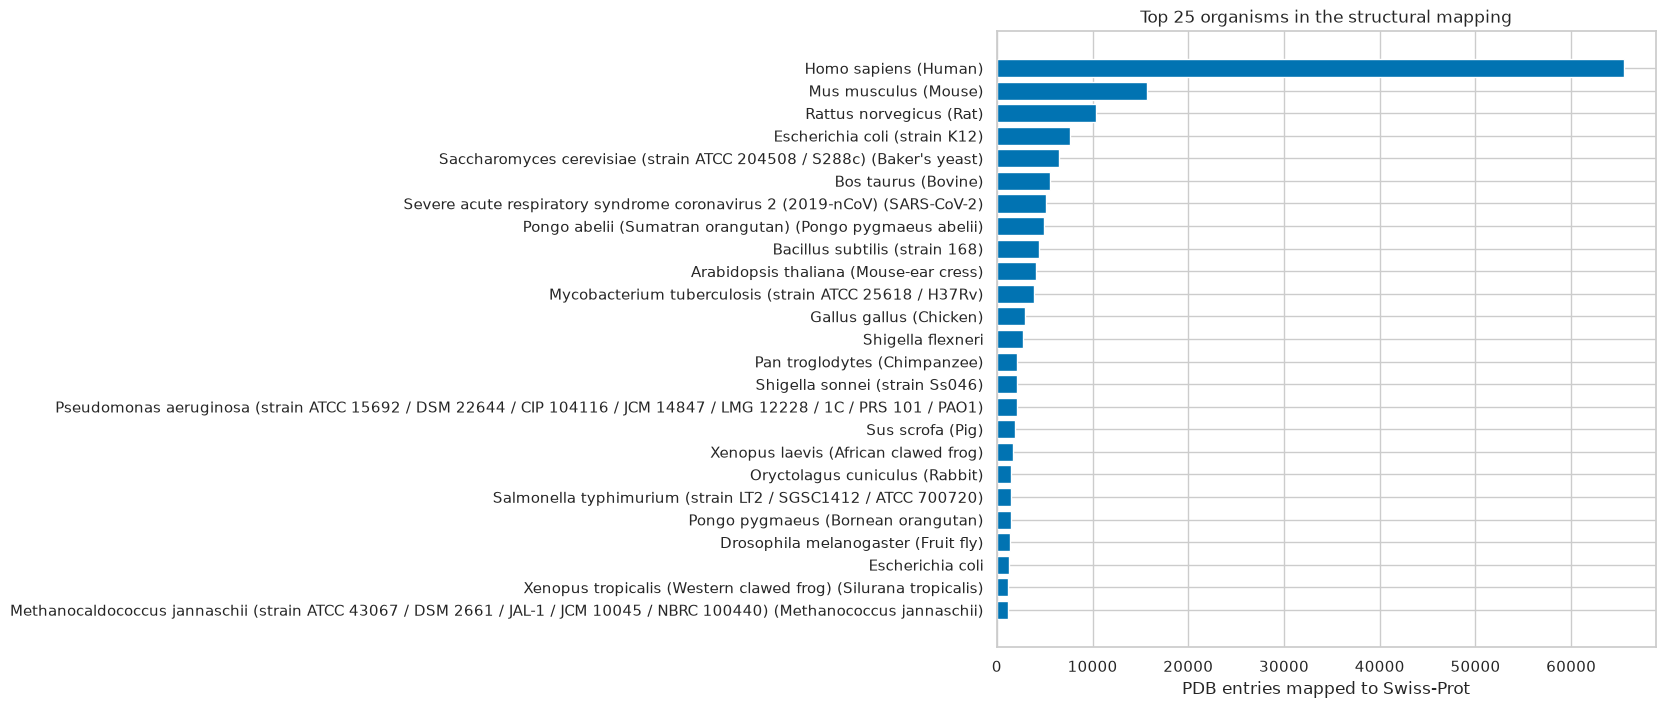

In [9]:
org_struct = query_df("""
    SELECT U.organism,
           COUNT(DISTINCT V.pdb_id) AS n_pdb_entries,
           COUNT(DISTINCT V.uniprot_acc) AS n_proteins,
           AVG(V.identity) AS mean_identity
    FROM view_pdb_uniprot V
    JOIN uniprot U ON U.uniprot_acc = V.uniprot_acc
    WHERE U.organism IS NOT NULL
    GROUP BY U.organism
    ORDER BY n_pdb_entries DESC
    LIMIT 25
""")
org_struct['n_pdb_entries'] = org_struct['n_pdb_entries'].astype(int)
org_struct['n_proteins'] = org_struct['n_proteins'].astype(int)
org_struct['mean_identity'] = org_struct['mean_identity'].astype(float).round(3)
save_csv(org_struct, 'integration_top_organisms')

fig, ax = plt.subplots(figsize=(8.5, 8))
os_ = org_struct.iloc[::-1]
ax.barh(os_['organism'], os_['n_pdb_entries'], color=PALETTE[0],
        label='PDB entries')
ax.set_title('Top 25 organisms in the structural mapping')
ax.set_xlabel('PDB entries mapped to Swiss-Prot')
save_fig(fig, 'integration_top_organisms')
org_struct.head(10)

## 7. Structural flexibility versus sequence conservation

Finally a genuinely integrative question: **do conserved proteins crystallize
into more rigid structures?** We join chain-level mean B-factors (from
`pdb_bfactor`) to the mapping and correlate B-factor against blastp identity.
A significant negative relation would suggest conserved cores are also
structurally more ordered in the crystal.

saved table: /home/yuan/bio/bio_omics/doc/stats/integration_bfactor_identity_correlation.csv  shape=(1, 5)
Spearman rho=-0.0515, p=1.808e-117, n=200000
saved figure: /home/yuan/bio/bio_omics/doc/figures/integration_bfactor_vs_identity.png


,comparison,method,n,rho,p_value
0,chain identity vs mean B-factor,spearman,200000,-0.0515,1.807501e-117


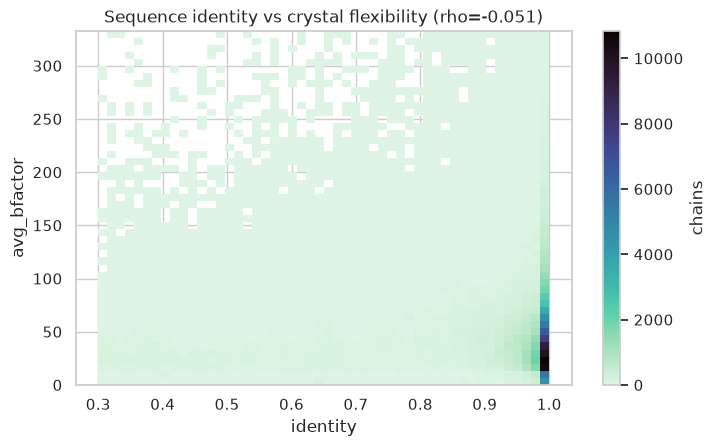

In [10]:
bf_ident = query_df("""
    SELECT V.identity, B.avg_bfactor
    FROM view_pdb_uniprot V
    JOIN pdb_bfactor B
      ON B.pdb_id = V.pdb_id
     AND B.model_no = CAST(SUBSTRING_INDEX(SUBSTRING_INDEX(V.chain_id, '_', 2), '_', -1) AS UNSIGNED)
     AND B.chain_no = SUBSTRING_INDEX(SUBSTRING_INDEX(V.chain_id, '_', 3), '_', -1)
    WHERE B.avg_bfactor IS NOT NULL
    LIMIT 200000
""")
bf_ident = bf_ident.dropna()
bf_ident['identity'] = bf_ident['identity'].astype(float)
bf_ident['avg_bfactor'] = bf_ident['avg_bfactor'].astype(float)

rho_b, p_b = stats.spearmanr(bf_ident['identity'], bf_ident['avg_bfactor'])
corr_b = pd.DataFrame([
    {'comparison': 'chain identity vs mean B-factor',
     'method': 'spearman', 'n': len(bf_ident),
     'rho': round(rho_b, 4), 'p_value': p_b},
])
save_csv(corr_b, 'integration_bfactor_identity_correlation')
print(f'Spearman rho={rho_b:.4f}, p={p_b:.3e}, n={len(bf_ident)}')

clip = bf_ident['avg_bfactor'].quantile(0.99)
fig, ax = plt.subplots(figsize=(8, 4.6))
sns.histplot(data=bf_ident[bf_ident['avg_bfactor'] <= clip],
             x='identity', y='avg_bfactor', bins=50, cmap='mako_r',
             cbar=True, cbar_kws={'label': 'chains'}, ax=ax)
ax.set_ylim(0, clip)
ax.set_title(f'Sequence identity vs crystal flexibility (rho={rho_b:.3f})')
save_fig(fig, 'integration_bfactor_vs_identity')
corr_b

## Summary

This notebook exported:

- figures: `integration_uniprot_pdb_venn`, `integration_identity_distribution`,
  `integration_resolution_vs_identity`, `integration_identity_by_method`,
  `integration_mutation_rate`, `integration_substitution_matrix`,
  `integration_top_organisms`, `integration_bfactor_vs_identity` -> `doc/figures/`
- statistical tables: coverage, venn set sizes, identity stats, correlations +
  tests, mutation-rate stats and per-chain rates, substitution counts,
  organisms -> `doc/stats/`

In [11]:
written = sorted(p.name for p in STAT_DIR.glob('integration_*.csv'))
print('statistical tables ready for further analysis:')
for name in written:
    df = pd.read_csv(STAT_DIR / name)
    print(f'  {name:45s} shape={df.shape}')

statistical tables ready for further analysis:
  integration_bfactor_identity_correlation.csv  shape=(1, 5)
  integration_coverage.csv                      shape=(9, 2)
  integration_identity_method_tests.csv         shape=(1, 9)
  integration_identity_resolution_correlation.csv shape=(1, 5)
  integration_identity_stats.csv                shape=(1, 9)
  integration_mutation_rate_stats.csv           shape=(1, 10)
  integration_mutation_rates.csv                shape=(19890, 1)
  integration_substitution_counts.csv           shape=(380, 3)
  integration_top_organisms.csv                 shape=(25, 4)
  integration_venn_sets.csv                     shape=(4, 2)
